# 04b - Logistic regression (reference baseline) kidney-stone risk model (`nhanes_v003b`)

A regularised logistic regression on the same standardised features, frozen splits, calibration, threshold rules and metric code. It is the **reference baseline** for the boosted models and is not registered for the app. CPU only. Imbalance strategy `class weights` means `class_weight='balanced'`.

**Ground rules.** Same frozen cycle-based split as `nhanes_v003` (train 2007-2014, validation 2015-2016, test 2017-2018), same features, same banned columns. The test cycle keeps its real ~10% prevalence, is never resampled and is never used to choose a threshold, hyper-parameters, a balancing method or features; it is first touched in section 10. Resampling (where used) happens only on **training** rows, inside the fit step of an `imblearn` Pipeline. The validation cycle is never resampled; it is split by `SEQN` (stratified) into an **early-stopping half** and a **calibration / threshold half** so the rows that decide where boosting stops are not the rows that calibrate probabilities and place thresholds.

**Two operating points**, both chosen on the validation calibration half only: `balanced` = maximum balanced accuracy; `accuracy` = maximum sensitivity subject to validation accuracy >= 72% (a margin above the 70% goal). About 90% of participants have no stone, so 'no stone for everyone' already scores ~90% accuracy; reaching > 70% accuracy is cheap and is bought with sensitivity. ROC-AUC and balanced accuracy are not expected to exceed 70%.

Every metric table in this notebook comes from one helper, `nhanes_common.show_metrics_table`.

Sections: 1 setup / device - 2 frozen splits and validation halves - 3 model + baseline fit - 4 class-imbalance comparison - 5 tuning - 6 calibration - 7 operating points - 8 leave-one-cycle-out CV - 9 freeze - 10 FINAL test evaluation - 11 imbalance strategies on test (display only) - 12 explanations - 13 save artifacts.

## 1. Setup and device check

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "ml" / "training" / "nhanes_common.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
from IPython.display import Image, display

from ml.training import nhanes_common as nc

nc.set_seeds()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
print("repo root:", ROOT.name)
print("dry run (test cycle untouched, outputs in ml/outputs/_dryrun):", nc.is_dry_run())

NOTEBOOK_FILE = "04b_logistic_regression_baseline.ipynb"
MODEL_KEY = "logreg"
MODEL_NAME = f"{MODEL_KEY}_{nc.RUN_TAG}"
timer = nc.Timer()
devices = nc.probe_devices()
print(json.dumps(devices, indent=1))
print("libraries:", json.dumps(nc.library_versions()))
print("registered model name:", MODEL_NAME)

repo root: StoneSense-AI
dry run (test cycle untouched, outputs in ml/outputs/_dryrun): False


{
 "nvidia_smi": "NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB, 592.15",
 "xgboost_cuda": true,
 "catboost_gpu": true,
 "lightgbm_gpu": false
}


libraries: {"python": "3.12.9", "numpy": "2.5.3", "pandas": "3.0.5", "sklearn": "1.9.0", "imblearn": "0.14.2", "xgboost": "3.4.1", "catboost": "1.2.10", "lightgbm": "4.7.0", "interpret": "0.7.8", "shap": "0.52.0", "joblib": "1.6.0"}
registered model name: logreg_nhanes_v003b


## 2. Load the frozen splits and cut the validation cycle in two

Only train and validation rows are loaded here. The preprocessor (median imputer, scaler, one-hot) is fit on the **training cycles only**. The validation cycle is split by `SEQN` into an **early-stopping half** (stopping point and tuning score) and a **calibration / threshold half** (strategy selection, calibration, both operating thresholds and every validation table). Neither half is resampled.

In [2]:
cfg = nc.load_feature_config()
splits = nc.load_frozen_splits(include_test=False)
manifest = nc.load_json(nc.artifacts_dir() / "split_manifest.json")
PRIMARY = cfg["primary_variant"]
dev_df = pd.concat([splits["train"], splits["validation"]], ignore_index=True)
print("split hash:", manifest["hash"][:16], "| train", len(splits["train"]), "| validation", len(splits["validation"]),
      "| positive rate train/val:", round(100 * splits["train"].target_stone.mean(), 2), "/", round(100 * splits["validation"].target_stone.mean(), 2), "%")
print("registered variant:", PRIMARY)
data = {v: nc.prepare_variant(splits, v, feats) for v, feats in cfg["variants"].items()}
print({v: len(vd.features) for v, vd in data.items()}, "features per variant")
assert not any(set(vd.features) & set(("KIQ026", "KIQ029", "SEQN", "CYCLE", "target_stone")) for vd in data.values())

# the validation cycle is cut (by SEQN, stratified) into an early-stopping half and a calibration / threshold half
halves = nc.split_validation(splits["validation"]["SEQN"].values, data[PRIMARY].y_val)
ES, CAL = halves["es"], halves["cal"]
VAL = {v: dict(Xes=vd.X_val[ES], yes=vd.y_val[ES], Xcal=vd.X_val[CAL], ycal=vd.y_val[CAL]) for v, vd in data.items()}
CAT = {v: nc.categorical_column_indices(vd.feature_names) for v, vd in data.items()}
print(f"validation early-stopping half: n={len(ES)} positives={int(VAL[PRIMARY]['yes'].sum())} ({100 * VAL[PRIMARY]['yes'].mean():.2f}%) | "
      f"calibration/threshold half: n={len(CAL)} positives={int(VAL[PRIMARY]['ycal'].sum())} ({100 * VAL[PRIMARY]['ycal'].mean():.2f}%) | halves hash {halves['hash'][:12]}")
print("categorical columns kept valid by SMOTENC (registered variant):", [data[PRIMARY].feature_names[i] for i in CAT[PRIMARY]])

split hash: a2c3bdb15ffb9f3b | train 23416 | validation 5705 | positive rate train/val: 8.86 / 10.62 %
registered variant: base_history_sensitive


{'base': 17, 'base_history': 21, 'base_history_sensitive': 23} features per variant
validation early-stopping half: n=2852 positives=303 (10.62%) | calibration/threshold half: n=2853 positives=303 (10.62%) | halves hash 06045bb720e5
categorical columns kept valid by SMOTENC (registered variant): ['RIAGENDR', 'BPQ020', 'BPQ080', 'DIQ010', 'MCQ080', 'RIDRETH1_1.0', 'RIDRETH1_2.0', 'RIDRETH1_3.0', 'RIDRETH1_4.0', 'RIDRETH1_5.0']


## 3. Model definition

Default hyper-parameters are fixed up front; early stopping (where it exists) watches **ROC-AUC on the early-stopping half only**.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

DEVICE = "cpu"
print("Logistic regression trains on: CPU")
N_TRIALS = 4 if nc.is_dry_run() else 15
REFIT_FIXED = False
DEFAULT_PARAMS = dict(C=0.1)

def sample_params(rng):
    return dict(C=float(10 ** rng.uniform(-3, 1)))

def _fit(params, strategy, Xtr, ytr, cat_idx):
    est = LogisticRegression(**params, class_weight="balanced" if strategy == "class_weight" else None, max_iter=3000, random_state=nc.SEED)
    return nc.fit_with_strategy(est, strategy, Xtr, ytr, cat_idx).named_steps["clf"]

def fit_es(Xtr, ytr, Xes, yes, params, strategy, cat_idx):
    return _fit(params, strategy, Xtr, ytr, cat_idx), None, None

def fit_fixed(Xtr, ytr, params, n_trees, strategy, cat_idx):
    return _fit(params, strategy, Xtr, ytr, cat_idx)

def finalize_estimator(m):
    return m

def actual_device(m):
    return "cpu"

Logistic regression trains on: CPU


### Baseline fit

Default hyper-parameters, **no balancing**, raw scores, every feature variant. Threshold-dependent columns use each score vector's own validation operating points (balanced / accuracy rules), because raw scores have no natural cut-off.

In [4]:
results = {"model": MODEL_KEY, "model_name": MODEL_NAME, "variants": {}}
base_entries, base_extra = {}, {}
for v, vd in data.items():
    clf, best_it, rounds = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], DEFAULT_PARAMS, "none", CAT[v])
    p = clf.predict_proba(VAL[v]["Xcal"])[:, 1]
    base_entries[v] = (VAL[v]["ycal"], p)
    base_extra[v] = {"best_iter": best_it, "rounds": rounds}
    results["variants"][v] = {"features": vd.features, "baseline_validation": {**nc.rank_metrics(VAL[v]["ycal"], p), "best_iteration": best_it, "rounds_trained": rounds}}
print("device actually used for training:", actual_device(clf))
baseline_table = nc.show_metrics_table(base_entries, "BASELINE fit - default params, no balancing, raw scores - validation (calibration half)",
                                       name=f"{MODEL_KEY}_01_baseline", extra=base_extra)
timer.lap("baseline")

device actually used for training: cpu
=== METRICS TABLE: BASELINE fit - default params, no balancing, raw scores - validation (calibration half) ===
        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN   FP  FN  TP best_iter rounds
                  base balanced    0.1029   0.635  0.173 0.0929    0.675        0.613       0.535       0.691     0.171 0.259 0.148        0.894         0.333 1763  787 141 162      None   None
                  base accuracy    0.1128   0.635  0.173 0.0929    0.720        0.596       0.439       0.754     0.175 0.250 0.134        0.894         0.267 1922  628 170 133      None   None
          base_history balanced    0.0815   0.645  0.181 0.0926    0.571        0.609       0.657       0.561     0.151 0.246 0.135        0.894         0.462 1431 1119 104 199      None   None
          base_history accuracy    0.1118   0.645  0.181 0.0926    0.720  

3.62

## 4. Class-imbalance comparison (registered variant, default hyper-parameters)

On the same frozen split: (i) **none**, (ii) **class weights** (`scale_pos_weight` / `sample_weight` / `class_weight`), (iii) **random oversampling**, (iv) **random undersampling**, (v) **SMOTENC**. Plain SMOTE would invent in-between values for the binary columns (sex, the yes/no history flags, the one-hot race columns), so SMOTENC is told which columns are categorical (printed in section 2). All resampling runs inside an `imblearn` Pipeline, so it only ever sees training rows.

Balanced training inflates raw probabilities (average predicted risk goes from ~10% towards ~50%), so every strategy is **calibrated on the real-prevalence validation calibration half** (isotonic vs sigmoid by cross-validated Brier). The strategy is selected on validation only by a rule declared in advance: best post-calibration PR-AUC; strategies within 0.005 PR-AUC are treated as tied and the lowest Brier then the simplest wins. The expectation that balancing mostly shifts the decision threshold and rarely improves ROC-AUC is **tested**, not assumed.

In [5]:
vd, V = data[PRIMARY], VAL[PRIMARY]
n_pos, n_neg = int(vd.y_train.sum()), int((vd.y_train == 0).sum())
rows_seen = {"none": n_pos + n_neg, "class_weight": n_pos + n_neg, "random_over": 2 * n_neg, "random_under": 2 * n_pos, "smotenc": 2 * n_neg}
strat_fit, strat_rows = {}, []
for s in nc.IMBALANCE_STRATEGIES:
    t0 = time.perf_counter()
    clf, bi, rounds = fit_es(vd.X_train, vd.y_train, V["Xes"], V["yes"], DEFAULT_PARAMS, s, CAT[PRIMARY])
    p_raw = clf.predict_proba(V["Xcal"])[:, 1]
    sel = nc.calibrated_oof_metrics(p_raw, V["ycal"])
    cal, rep = nc.choose_calibrator(p_raw, V["ycal"])
    strat_fit[s] = dict(clf=clf, cal=cal, p_raw=p_raw, p_cal=cal.predict(p_raw), best_iteration=bi)
    strat_rows.append({"strategy": s, "train_rows_fitted": rows_seen[s], "best_iter": bi, "mean_raw_risk": sel["mean_raw_risk"], **{k: sel[k] for k in
                       ("calibration_method", "mean_calibrated_risk", "oof_roc_auc", "oof_pr_auc", "oof_brier")}, "fit_seconds": round(time.perf_counter() - t0, 1)})
strat_table = pd.DataFrame(strat_rows).set_index("strategy")
print("Strategy comparison, registered variant, default hyper-parameters. Resampling touched TRAINING rows only; validation/test keep their real prevalence")
print(f"(validation calibration half prevalence = {100 * V['ycal'].mean():.2f}%). 'oof_*' = cross-validated metrics of the CALIBRATED probabilities.")
print(strat_table.round(4).to_string())
SELECTED, select_info = nc.select_strategy(strat_table)
print(f"\nSELECTED strategy (validation only; rule: best post-calibration PR-AUC, strategies within {nc.STRATEGY_TIE_BAND} PR-AUC tie, then lowest Brier): "
      f"{SELECTED} ({nc.STRATEGY_LABEL[SELECTED]})")
print("tied with:", select_info["tied_with"], "| 'none' within the tie band:", select_info["none_within_tie_band"],
      "| PR-AUC gain of the selection over 'none':", round(select_info["pr_auc_gain_over_none"], 4))
print("ROC-AUC range across strategies after calibration:", round(strat_table.oof_roc_auc.min(), 4), "-", round(strat_table.oof_roc_auc.max(), 4))
strat_val_table = nc.show_metrics_table({s: (V["ycal"], strat_fit[s]["p_cal"]) for s in nc.IMBALANCE_STRATEGIES},
                                        "IMBALANCE STRATEGIES (each calibrated on the real-prevalence validation half; thresholds from validation) - validation",
                                        name=f"{MODEL_KEY}_02_imbalance_validation",
                                        extra={s: {"mean_raw_risk": round(strat_table.loc[s, "mean_raw_risk"], 3)} for s in nc.IMBALANCE_STRATEGIES})
timer.lap("imbalance_comparison")

Strategy comparison, registered variant, default hyper-parameters. Resampling touched TRAINING rows only; validation/test keep their real prevalence
(validation calibration half prevalence = 10.62%). 'oof_*' = cross-validated metrics of the CALIBRATED probabilities.
              train_rows_fitted best_iter  mean_raw_risk calibration_method  mean_calibrated_risk  oof_roc_auc  oof_pr_auc  oof_brier  fit_seconds
strategy                                                                                                                                          
none                      23416      None         0.0877            sigmoid                0.1062       0.6502      0.1815     0.0921          0.1
class_weight              23416      None         0.4525            sigmoid                0.1063       0.6500      0.1795     0.0922          0.1
random_over               42684      None         0.4530            sigmoid                0.1063       0.6503      0.1806     0.0922          0.

1.83

## 5. Hyper-parameter tuning with the selected strategy

Random search scored by **validation ROC-AUC on the early-stopping half** (PR-AUC is logged alongside); the first trial is the default configuration. Never the test cycle. Exactly the one strategy selected in section 4 is used (no stacking of weights and resampling).

In [6]:
tuning, estimators, n_trees, p_val_raw, rounds_trained = {}, {}, {}, {}, {}
for v, vd in data.items():
    def fit_eval(params, vd=vd, v=v):
        clf, bi, _ = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], params, SELECTED, CAT[v])
        p = clf.predict_proba(VAL[v]["Xes"])[:, 1]
        return {"val_roc_auc": float(roc_auc_score(VAL[v]["yes"], p)), "val_pr_auc": float(average_precision_score(VAL[v]["yes"], p)),
                "n_trees": bi}
    best, trials = nc.random_search(sample_params, fit_eval, N_TRIALS, seed=nc.SEED, first_params=DEFAULT_PARAMS)
    clf, bi, rounds = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], best, SELECTED, CAT[v])
    est = fit_fixed(vd.X_train, vd.y_train, best, bi, SELECTED, CAT[v]) if REFIT_FIXED else clf
    estimators[v], n_trees[v], rounds_trained[v] = est, bi, rounds
    p_val_raw[v] = est.predict_proba(VAL[v]["Xcal"])[:, 1]
    tuning[v] = {"best_params": best, "n_trials": int(len(trials)), "imbalance_strategy": SELECTED,
                 "tuning_score": "ROC-AUC on the validation early-stopping half", "best_val_roc_auc_es_half": float(trials["val_roc_auc"].max()),
                 "best_iteration": bi, "rounds_trained": rounds, "n_trees": bi,
                 "final_val_roc_auc_cal_half": float(roc_auc_score(VAL[v]["ycal"], p_val_raw[v]))}
    results["variants"][v]["tuning"] = tuning[v]
    nc.ensure(nc.metrics_dir())
    trials.to_csv(nc.metrics_dir() / f"{MODEL_KEY}_tuning_{v}.csv", index=False)
display(pd.DataFrame({v: {k: tuning[v][k] for k in ("n_trials", "best_val_roc_auc_es_half", "final_val_roc_auc_cal_half", "best_iteration", "rounds_trained")} for v in data}).T)
print("best params (registered variant):", tuning[PRIMARY]["best_params"])
print("imbalance strategy used for tuning and the final fit:", SELECTED)
TRAIN_DEVICE = actual_device(estimators[PRIMARY])      # recorded now: finalize_estimator() may later switch XGBoost to CPU for serving
print("device actually used for the final fit:", TRAIN_DEVICE)
tuned_table = nc.show_metrics_table({v: (VAL[v]["ycal"], p_val_raw[v]) for v in data},
                                    "AFTER TUNING - raw (uncalibrated) scores - validation (calibration half)", name=f"{MODEL_KEY}_03_tuned",
                                    extra={v: {"best_iter": tuning[v]["best_iteration"], "rounds": tuning[v]["rounds_trained"]} for v in data})
timer.lap("tuning_and_final_fit")

,n_trials,best_val_roc_auc_es_half,final_val_roc_auc_cal_half,best_iteration,rounds_trained
base,15.0,0.606438,0.635965,NaN,NaN
base_history,15.0,0.631654,0.644264,NaN,NaN
base_history_sensitive,15.0,0.658634,0.653395,NaN,NaN


best params (registered variant): {'C': 0.0314891164795686}
imbalance strategy used for tuning and the final fit: none
device actually used for the final fit: cpu
=== METRICS TABLE: AFTER TUNING - raw (uncalibrated) scores - validation (calibration half) ===
        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN   FP  FN  TP best_iter rounds
                  base balanced    0.1012   0.636  0.173 0.0930    0.663        0.612       0.548       0.677     0.168 0.257 0.145        0.894         0.347 1726  824 137 166      None   None
                  base accuracy    0.1111   0.636  0.173 0.0930    0.720        0.607       0.462       0.751     0.181 0.260 0.148        0.894         0.272 1915  635 163 140      None   None
          base_history balanced    0.0703   0.644  0.183 0.0927    0.482        0.607       0.766       0.448     0.142 0.239 0.133        0.894         0.574 

1.4

## 6. Probability calibration on the validation calibration half

Isotonic and sigmoid are compared by **Brier score** (cross-validated inside the calibration half, so isotonic does not win just by over-fitting); the winner is refit on all calibration-half rows and then **frozen**. Calibration restores the real prevalence: the average predicted risk should land near the real ~10%.

In [7]:
calibrators, p_val_cal = {}, {}
for v, vd in data.items():
    cal, rep = nc.choose_calibrator(p_val_raw[v], VAL[v]["ycal"])
    rep["mean_raw_risk"] = float(np.clip(p_val_raw[v], 0, 1).mean())
    rep["mean_calibrated_risk"] = float(cal.predict(p_val_raw[v]).mean())
    rep["validation_prevalence"] = float(VAL[v]["ycal"].mean())
    calibrators[v], p_val_cal[v] = cal, cal.predict(p_val_raw[v])
    results["variants"][v]["calibration"] = rep
display(pd.DataFrame({v: results["variants"][v]["calibration"] for v in data}).T.round(5))
print("average predicted risk BEFORE -> AFTER calibration (registered variant):",
      round(results["variants"][PRIMARY]["calibration"]["mean_raw_risk"], 4), "->", round(results["variants"][PRIMARY]["calibration"]["mean_calibrated_risk"], 4),
      "| real validation prevalence:", round(results["variants"][PRIMARY]["calibration"]["validation_prevalence"], 4))
p = nc.plot_calibration({"raw model output": (VAL[PRIMARY]["ycal"], np.clip(p_val_raw[PRIMARY], 0, 1)),
                         f"calibrated ({results['variants'][PRIMARY]['calibration']['method']})": (VAL[PRIMARY]["ycal"], p_val_cal[PRIMARY])},
                        nc.charts_dir() / f"{MODEL_KEY}_calibration_validation.png",
                        f"{MODEL_KEY}: validation calibration half (calibrator fitted here)")
print("saved", p.name)
calibrated_table = nc.show_metrics_table({v: (VAL[v]["ycal"], p_val_cal[v]) for v in data},
                                         "AFTER CALIBRATION - calibrated probabilities - validation (calibration half)",
                                         name=f"{MODEL_KEY}_04_calibrated",
                                         extra={v: {"calibration": results["variants"][v]["calibration"]["method"]} for v in data})
timer.lap("calibration")

,method,cv_brier_isotonic,cv_brier_sigmoid,brier_raw_uncalibrated,brier_calibrated_in_sample,mean_raw_risk,mean_calibrated_risk,validation_prevalence
base,sigmoid,0.093625,0.093004,0.092985,0.092661,0.089908,0.106207,0.106204
base_history,sigmoid,0.092684,0.092616,0.092676,0.092375,0.089754,0.106205,0.106204
base_history_sensitive,isotonic,0.091558,0.092115,0.092146,0.090047,0.087845,0.106204,0.106204


average predicted risk BEFORE -> AFTER calibration (registered variant): 0.0878 -> 0.1062 | real validation prevalence: 0.1062
saved logreg_calibration_validation.png
=== METRICS TABLE: AFTER CALIBRATION - calibrated probabilities - validation (calibration half) ===


        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN   FP  FN  TP calibration
                  base balanced    0.1198   0.636  0.173 0.0927    0.663        0.612       0.548       0.677     0.168 0.257 0.145        0.894         0.347 1726  824 137 166     sigmoid
                  base accuracy    0.1313   0.636  0.173 0.0927    0.720        0.607       0.462       0.751     0.181 0.260 0.148        0.894         0.272 1915  635 163 140     sigmoid
          base_history balanced    0.0846   0.644  0.183 0.0924    0.482        0.607       0.766       0.448     0.142 0.239 0.133        0.894         0.574 1143 1407  71 232     sigmoid
          base_history accuracy    0.1307   0.644  0.183 0.0924    0.720        0.604       0.455       0.752     0.179 0.257 0.144        0.894         0.270 1917  633 165 138     sigmoid
base_history_sensitive balanced    0.1254   0.664  0.19

0.18

## 7. Operating points, chosen on the validation calibration half

Both rules use the calibrated validation probabilities only:

1. **`balanced`**: the cut-off that maximises balanced accuracy (mean of sensitivity and specificity).
2. **`accuracy`**: the cut-off that maximises **sensitivity subject to validation accuracy >= 72%** (the lowest cut-off whose validation accuracy is at least 72%). If no cut-off reaches 72%, it is reported as unreachable.

In [8]:
thr_rows = []
for v, vd in data.items():
    ops = nc.operating_points(VAL[v]["ycal"], p_val_cal[v])
    results["variants"][v]["thresholds"] = ops
    ev = nc.evaluate_scores(VAL[v]["ycal"], p_val_cal[v], {pt: None if ops[pt] is None else ops[pt]["threshold"] for pt in nc.OPERATING_POINTS})
    results["variants"][v]["validation"] = ev
    for pt in nc.OPERATING_POINTS:
        o = ops[pt]
        thr_rows.append({"variant": v, "point": pt, "threshold": None if o is None else round(o["threshold"], 4),
                         "val_accuracy": None if o is None else round(o["accuracy"], 4), "val_sensitivity": None if o is None else round(o["sensitivity"], 4),
                         "val_specificity": None if o is None else round(o["specificity"], 4), "flagged": None if o is None else round(o["positive_rate"], 4)})
    if ops[nc.OP_ACCURACY] is not None:
        assert ops[nc.OP_ACCURACY]["accuracy"] >= nc.ACC_TARGET_VALIDATION - 1e-12
display(pd.DataFrame(thr_rows).set_index(["variant", "point"]))
print("validation majority-class accuracy:", round(results["variants"][PRIMARY]["validation"]["majority_baseline_accuracy"], 4))
unreachable = [v for v in data if results["variants"][v]["thresholds"][nc.OP_ACCURACY] is None]
print("variants where accuracy >=", nc.ACC_TARGET_VALIDATION, "was unreachable on validation:", unreachable or "none")
timer.lap("thresholds")

threshold  val_accuracy  val_sensitivity  val_specificity  flagged
variant                point                                                                       
base                   balanced     0.1198        0.6632           0.5479           0.6769   0.3470
                       accuracy     0.1313        0.7203           0.4620           0.7510   0.2716
base_history           balanced     0.0846        0.4819           0.7657           0.4482   0.5745
                       accuracy     0.1307        0.7203           0.4554           0.7518   0.2702
base_history_sensitive balanced     0.1254        0.6085           0.6337           0.6055   0.4199
                       accuracy     0.1429        0.8412           0.2376           0.9129   0.1030

validation majority-class accuracy: 0.8938
variants where accuracy >= 0.72 was unreachable on validation: none


0.02

## 8. Stability across survey cycles (leave-one-cycle-out CV)

Train on four of the five train+validation cycles with the tuned configuration and the selected strategy, score the fifth. Scores are uncalibrated, so the cut-off of each operating point is placed by the **fraction of people it flags on validation** (no held-out label is used). Per-fold accuracy and sensitivity are shown with their mean and spread.

In [9]:
loco_rows, loco_fold_rows = [], []
for v, vd in data.items():
    ops = results["variants"][v]["thresholds"]
    rates = {pt: ops[pt]["positive_rate"] for pt in nc.OPERATING_POINTS if ops[pt] is not None}
    best = tuning[v]["best_params"]
    def fp(Xtr, ytr, Xho, best=best, v=v):
        return fit_fixed(Xtr, ytr, best, n_trees[v], SELECTED, CAT[v]).predict_proba(Xho)[:, 1]
    loco = nc.loco_cv(dev_df, vd.features, fp, nc.TRAIN_CYCLES + nc.VAL_CYCLES, flag_rates=rates)
    results["variants"][v]["loco_cv"] = loco
    row = {"variant": v, "roc_auc": f"{loco['roc_auc_mean']:.4f} +/- {loco['roc_auc_std']:.4f}", "pr_auc_mean": round(loco["pr_auc_mean"], 4)}
    for pt in rates:
        row[f"acc_{pt}"] = f"{loco[f'acc_{pt}_mean']:.3f} +/- {loco[f'acc_{pt}_std']:.3f}"
        row[f"sens_{pt}"] = f"{loco[f'sens_{pt}_mean']:.3f} +/- {loco[f'sens_{pt}_std']:.3f}"
    loco_rows.append(row)
    if v == PRIMARY:
        for f in loco["folds"]:
            r = {"held-out cycle": f["held_out_cycle"], "n": f["n"], "prevalence": round(f["prevalence"], 4), "ROC-AUC": round(f["roc_auc"], 4)}
            for pt in rates:
                r[f"Accuracy ({pt})"], r[f"Sensitivity ({pt})"] = round(f[f"acc_{pt}"], 4), round(f[f"sens_{pt}"], 4)
            loco_fold_rows.append(r)
print("=== LEAVE-ONE-CYCLE-OUT CV, per fold (registered variant): accuracy and sensitivity at both operating points ===")
print("(cut-off placement: the top fraction of held-out scores that the validation-chosen operating point flags; no held-out label is used)")
print(pd.DataFrame(loco_fold_rows).to_string(index=False))
print("\n=== LOCO summary, mean +/- sd across the five cycles, all variants ===")
print(pd.DataFrame(loco_rows).set_index("variant").to_string())
timer.lap("loco_cv")

=== LEAVE-ONE-CYCLE-OUT CV, per fold (registered variant): accuracy and sensitivity at both operating points ===
(cut-off placement: the top fraction of held-out scores that the validation-chosen operating point flags; no held-out label is used)
held-out cycle    n  prevalence  ROC-AUC  Accuracy (balanced)  Sensitivity (balanced)  Accuracy (accuracy)  Sensitivity (accuracy)
     2007-2008 5909      0.0912   0.6806               0.6135                  0.6827               0.8443                  0.2115
     2009-2010 6201      0.0874   0.6833               0.6123                  0.6845               0.8473                  0.2159
     2011-2012 5548      0.0826   0.6775               0.6063                  0.6594               0.8511                  0.2227
     2013-2014 5758      0.0929   0.6767               0.6070                  0.6449               0.8460                  0.2262
     2015-2016 5705      0.1062   0.6560               0.6077                  0.6304              

0.99

## 9. Freeze the models

Each (preprocessor, estimator, calibrator, thresholds) bundle is written to disk **before** the test cycle is touched, and a fingerprint of the frozen configuration is computed. The test-evaluation helper refuses to re-score a model whose fingerprint differs from the one it already scored. Bundles for the five strategies of section 4 are frozen too so they can be shown on test for information only.

In [10]:
import joblib

bundles, fingerprints, strat_bundles, strat_fp = {}, {}, {}, {}
for v, vd in data.items():
    t = results["variants"][v]["thresholds"]
    thr = {pt: None if t[pt] is None else t[pt]["threshold"] for pt in nc.OPERATING_POINTS}
    bundle = nc.make_bundle(MODEL_NAME, MODEL_KEY, v, vd, finalize_estimator(estimators[v]), calibrators[v], thr,
                            metadata={"best_params": tuning[v]["best_params"], "n_trees": n_trees[v], "split_hash": manifest["hash"],
                                      "calibration": results["variants"][v]["calibration"]["method"], "imbalance_strategy": SELECTED})
    # the bundle (raw rows in -> calibrated probability out) must reproduce the notebook's validation scores
    np.testing.assert_allclose(bundle.predict_proba_raw(splits["validation"])[CAL], p_val_raw[v], atol=1e-4)
    path = nc.ensure(nc.bundles_dir()) / f"{MODEL_NAME}__{v}.joblib"
    joblib.dump(bundle, path)
    results["variants"][v]["bundle_path"] = str(path)
    results["variants"][v]["bundle_sha256"] = nc.file_sha256(path)
    bundles[v] = bundle
    fingerprints[v] = nc.frozen_fingerprint(MODEL_NAME, v, {**tuning[v]["best_params"], "imbalance": SELECTED}, vd.features,
                                            results["variants"][v]["calibration"]["method"], thr, manifest["hash"])
# bundles for the five imbalance strategies of section 4 (default hyper-parameters; evaluated for DISPLAY only after the selection above)
for s, f in strat_fit.items():
    ops_s = nc.operating_points(VAL[PRIMARY]["ycal"], f["p_cal"])
    thr_s = {pt: None if ops_s[pt] is None else ops_s[pt]["threshold"] for pt in nc.OPERATING_POINTS}
    f["thresholds"], f["operating_points"] = thr_s, ops_s
    strat_bundles[s] = nc.make_bundle(f"{MODEL_NAME}__imb_{s}", MODEL_KEY, PRIMARY, data[PRIMARY], finalize_estimator(f["clf"]), f["cal"], thr_s)
    strat_fp[s] = nc.frozen_fingerprint(f"{MODEL_NAME}__imb_{s}", PRIMARY, {**DEFAULT_PARAMS, "imbalance": s}, data[PRIMARY].features,
                                        f["cal"].method, thr_s, manifest["hash"])
print({v: (fingerprints[v][:10], results["variants"][v]["bundle_sha256"][:10]) for v in data})
timer.lap("freeze")

{'base': ('c439a7eea7', '63326fb62d'), 'base_history': ('266a515b7f', '8df4728642'), 'base_history_sensitive': ('e6a0f7e471', '0bf6f0c1ad')}


0.05

## 10. FINAL test-set evaluation (2017-2018)

The frozen model is scored on the held-out test cycle with 1,000-sample bootstrap 95% confidence intervals, at **both** operating points. Nothing is tuned afterwards. 'Majority acc' is the accuracy of predicting *no stone* for everyone.

evaluated on: test (2017-2018) | n = 5558 | prevalence = 0.0997 | majority-class (predict 'no stone' for all) accuracy = 0.9003
=== METRICS TABLE: FINAL TEST EVALUATION - both operating points - bootstrap 95% CI (1,000 resamples) - held-out 2017-2018 ===
        model/strategy    point Threshold              ROC-AUC               PR-AUC                   Brier             Accuracy         Balanced acc          Sensitivity          Specificity            Precision                   F1                  MCC Majority acc        Pos-pred rate   TN   FP  FN  TP
                  base balanced    0.1198 0.623 [0.598, 0.647] 0.158 [0.138, 0.183] 0.0882 [0.0824, 0.0941] 0.629 [0.616, 0.641] 0.576 [0.553, 0.598] 0.511 [0.469, 0.550] 0.642 [0.629, 0.655] 0.136 [0.121, 0.150] 0.215 [0.194, 0.235] 0.095 [0.066, 0.121]        0.900 0.373 [0.361, 0.385] 3213 1791 271 283
                  base accuracy    0.1313 0.623 [0.598, 0.647] 0.158 [0.138, 0.183] 0.0882 [0.0824, 0.0941] 0.693 [0.681, 0.705] 0.

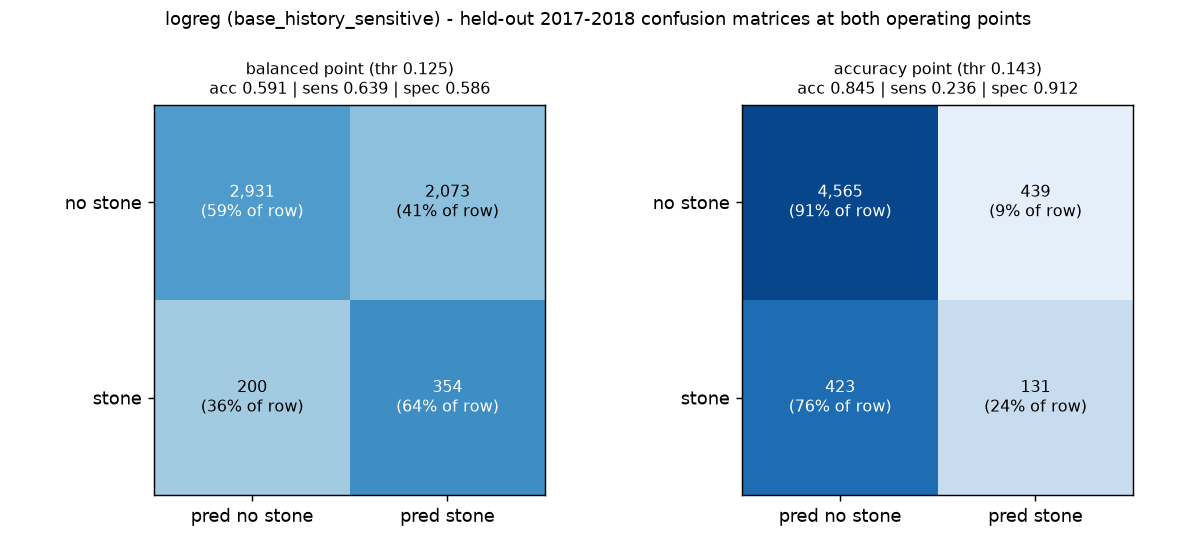

accuracy goal (> 70%) on the held-out test cycle: REACHED - accuracy 0.845, sensitivity 0.236, specificity 0.912 (majority baseline 0.900)


9.38

In [11]:
test_out = {}
for v in data:
    out = nc.final_test_evaluation(bundles[v], MODEL_NAME, v, fingerprints[v])
    results["variants"][v]["test"] = out["result"]
    test_out[v] = out
print("evaluated on:", results["variants"][PRIMARY]["test"]["evaluated_on"], "| n =", results["variants"][PRIMARY]["test"]["n"],
      "| prevalence =", round(results["variants"][PRIMARY]["test"]["prevalence"], 4),
      "| majority-class (predict 'no stone' for all) accuracy =", round(results["variants"][PRIMARY]["test"]["majority_baseline_accuracy"], 4))
final_table = nc.show_metrics_table(None, "FINAL TEST EVALUATION - both operating points - bootstrap 95% CI (1,000 resamples) - held-out 2017-2018",
                                    name=f"{MODEL_KEY}_06_final_test", results={v: results["variants"][v]["test"] for v in data})
p = nc.plot_calibration({v: (test_out[v]["y"], test_out[v]["p"]) for v in data}, nc.charts_dir() / f"{MODEL_KEY}_calibration_test.png",
                        f"{MODEL_KEY}: held-out test calibration")
thr_primary = {pt: bundles[PRIMARY].thresholds[pt] for pt in nc.OPERATING_POINTS}
cm_path = nc.plot_confusion_matrices(test_out[PRIMARY]["y"], test_out[PRIMARY]["p"], thr_primary,
                                     nc.charts_dir() / f"{MODEL_KEY}_confusion_test.png",
                                     f"{MODEL_KEY} ({PRIMARY}) - held-out 2017-2018 confusion matrices at both operating points")
display(Image(filename=str(cm_path)))
acc_pt = results["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_ACCURACY]
if acc_pt is not None:
    verdict = "REACHED" if acc_pt["accuracy"] > nc.ACC_GOAL_TEST else "NOT reached"
    print(f"accuracy goal (> {nc.ACC_GOAL_TEST:.0%}) on the held-out test cycle: {verdict} - accuracy {acc_pt['accuracy']:.3f}, "
          f"sensitivity {acc_pt['sensitivity']:.3f}, specificity {acc_pt['specificity']:.3f} (majority baseline "
          f"{results['variants'][PRIMARY]['test']['majority_baseline_accuracy']:.3f})")
timer.lap("final_test")

## 11. Imbalance strategies on the test cycle (display only)

The strategy was frozen in section 4 and the registered model in section 9; this cell only *shows* how each strategy (default hyper-parameters, validation-derived calibrators and thresholds) behaves on test. Nothing here feeds back into any choice.

In [12]:
strat_test = {}
for s in nc.IMBALANCE_STRATEGIES:
    strat_test[s] = nc.final_test_evaluation(strat_bundles[s], f"{MODEL_NAME}__imb_{s}", PRIMARY, strat_fp[s])["result"]
strat_test_table = nc.show_metrics_table(None, "IMBALANCE STRATEGIES - held-out TEST (display only; the strategy was frozen on validation before this cell) - bootstrap 95% CI",
                                         name=f"{MODEL_KEY}_05_imbalance_test", results=strat_test)
auc_tab = pd.DataFrame({s: {"test ROC-AUC": strat_test[s]["roc_auc"], "test PR-AUC": strat_test[s]["pr_auc"], "test Brier": strat_test[s]["brier"]}
                        for s in nc.IMBALANCE_STRATEGIES}).T
print("test ranking / calibration by strategy (default hyper-parameters):")
print(auc_tab.round(4).to_string())
print(f"validation-selected strategy: {SELECTED}. ROC-AUC spread across strategies on test: "
      f"{auc_tab['test ROC-AUC'].min():.4f} - {auc_tab['test ROC-AUC'].max():.4f}; 'none' = {auc_tab.loc['none', 'test ROC-AUC']:.4f}.")
timer.lap("strategy_test")

=== METRICS TABLE: IMBALANCE STRATEGIES - held-out TEST (display only; the strategy was frozen on validation before this cell) - bootstrap 95% CI ===
model/strategy    point Threshold              ROC-AUC               PR-AUC                   Brier             Accuracy         Balanced acc          Sensitivity          Specificity            Precision                   F1                  MCC Majority acc        Pos-pred rate   TN   FP  FN  TP
          none balanced    0.0977 0.661 [0.638, 0.685] 0.183 [0.161, 0.211] 0.0867 [0.0809, 0.0927] 0.577 [0.564, 0.590] 0.612 [0.592, 0.633] 0.655 [0.618, 0.695] 0.568 [0.554, 0.582] 0.144 [0.131, 0.158] 0.236 [0.217, 0.256] 0.135 [0.110, 0.160]        0.900 0.454 [0.441, 0.467] 2844 2160 191 363
          none accuracy    0.1284 0.661 [0.638, 0.685] 0.183 [0.161, 0.211] 0.0867 [0.0809, 0.0927] 0.723 [0.712, 0.735] 0.609 [0.589, 0.630] 0.468 [0.427, 0.508] 0.751 [0.740, 0.763] 0.172 [0.153, 0.191] 0.252 [0.227, 0.275] 0.148 [0.119, 0.176]      

15.62

## 12. Explanations

Global importance is computed on a sample of the **validation** cycle (never the test cycle) as the mean absolute per-feature contribution on the log-odds scale; one-hot columns are summed back to the raw feature. Contributions describe what the model uses, not causes.

In [13]:
imp = nc.global_importance(bundles[PRIMARY], splits["validation"])
display(imp.head(10).round(4))
nc.plot_importance(imp["feature"].tolist(), imp["mean_abs_contribution"].tolist(), nc.charts_dir() / f"{MODEL_KEY}_importance.png",
                   f"{MODEL_KEY}: top features ({PRIMARY})")
for v in data:
    results["variants"][v]["importance_validation"] = nc.global_importance(bundles[v], splits["validation"]).head(10).to_dict(orient="records")
ex = splits["validation"].loc[splits["validation"].target_stone == 1].head(1)
c = pd.Series(bundles[PRIMARY].contributions(ex)[0], index=bundles[PRIMARY].input_features)
print("Local explanation for one validation positive (top 5 by |contribution|):")
print(c.reindex(c.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

,feature,mean_abs_contribution
0,RIDRETH1,0.2756
1,RIDAGEYR,0.2086
2,LBXSCLSI,0.2038
3,BPQ020,0.1380
4,LBXSPH,0.1316
5,RIAGENDR,0.1258
6,MCQ080,0.1231
7,DIQ010,0.0844
8,LBXSKSI,0.0832
9,BPQ080,0.0788


Local explanation for one validation positive (top 5 by |contribution|):
RIDRETH1    0.395
LBXSPH     -0.170
RIAGENDR    0.130
LBXSKSI    -0.112
BPQ020     -0.108


## 13. Save artifacts

Metrics JSON (`ml/outputs/metrics/nhanes_v003/<model>.json`) with provenance (notebook file, execution timestamp, device, training time, library versions, split hash), calibration and importance plots, tuning tables, metric-table CSVs and the frozen bundles.

In [14]:
timer.lap("explanations")
fit_seconds = round(sum(timer.sections.get(k, 0) for k in ("baseline", "imbalance_comparison", "tuning_and_final_fit", "loco_cv", "calibration")), 2)
for v in data:   # per-variant bookkeeping used by notebook 05
    results["variants"][v]["imbalance"] = ({"selected": SELECTED, "table": strat_table.reset_index().to_dict(orient="records"), "selection": select_info,
                                            "test": {s: strat_test[s] for s in nc.IMBALANCE_STRATEGIES},
                                            "validation_operating_points": {s: strat_fit[s]["operating_points"] for s in nc.IMBALANCE_STRATEGIES}}
                                           if v == PRIMARY else {"selected": SELECTED, "note": "strategy selected on the registered variant"})
results.update({
    "primary_variant": PRIMARY, "split_hash": manifest["hash"], "split_counts": manifest["counts"],
    "split_positive_rate": manifest["positive_rate"], "seed": nc.SEED, "dry_run": nc.is_dry_run(),
    "validation_halves": {"hash": halves["hash"], "early_stopping_n": int(len(ES)), "calibration_n": int(len(CAL)),
                          "early_stopping_positives": int(VAL[PRIMARY]["yes"].sum()), "calibration_positives": int(VAL[PRIMARY]["ycal"].sum())},
    "imbalance_strategy": SELECTED, "operating_point_rule": {nc.OP_BALANCED: nc.OP_RULE[nc.OP_BALANCED], nc.OP_ACCURACY: nc.OP_RULE[nc.OP_ACCURACY]},
    "device": {"requested": DEVICE, "actual": TRAIN_DEVICE, "hardware": devices["nvidia_smi"], "probe": devices},
    "training_seconds": fit_seconds, "notebook_seconds": timer.total, "section_seconds": timer.sections,
    "trained_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
})
results["provenance"] = nc.provenance(NOTEBOOK_FILE, timer, results["device"], manifest["hash"], fit_seconds)
out = nc.save_json(results, nc.metrics_dir() / f"{MODEL_KEY}.json")
print("saved", nc.rel(out))
print(f"device used for training: {results['device']['actual']} | training time (fits + tuning + CV): {fit_seconds}s | notebook total: {timer.total}s")
print(f"PROVENANCE notebook={NOTEBOOK_FILE} executed_at={results['provenance']['executed_at']} split_hash={manifest['hash']}")

saved ml/outputs/metrics/nhanes_v003/logreg.json
device used for training: cpu | training time (fits + tuning + CV): 8.02s | notebook total: 33.22s
PROVENANCE notebook=04b_logistic_regression_baseline.ipynb executed_at=2026-10-15T08:47:32Z split_hash=a2c3bdb15ffb9f3b943ec517e878cd8c59a92c444acd15ef7e35446fd0fcc7e7
